In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. SIMULACIÓN DE DATOS DE LA PLANTA (24 HORAS DE MEDICIONES)

In [2]:
print("--- Generando datos de los sensores de la planta ----")

--- Generando datos de los sensores de la planta ----


## Creamos un rango de tiempo para un día completo, midiendo cada 15 minutos

In [3]:
horas = pd.date_range(start='2026-08-02 00:00', end='2026-08-02 23:45', freq='15min')

## Inicializamos el generador de números aleatorios para simular los sensores

In [4]:
np.random.seed(42)
presion_normal = np.random.normal(loc=450, scale=20, size=len(horas))
temperatura_normal = np.random.normal(loc=60, scale=5, size=len(horas))

## Creamos el DataFrame (nuestra tabla de control industrial)

In [5]:
df_planta = pd.DataFrame(
    {
    'Timestamp': horas,
    'Sensor_Presion_psi': presion_normal,
    'Sensor_Temp_C': temperatura_normal,
    'Estado_Valvula' : "ABIERTA",
    })

## Simulamos DOS ANOMALÍAS CRÍTICAS de sobrepresión en el sistema (Peligro)

In [6]:
df_planta.loc[12:15, "Sensor_Presion_psi"] = [530.5, 545.2, 552.1, 510.8]
df_planta.loc[60:62, "Sensor_Presion_psi"] = [515.3, 522.0, 508.4]

## Redondeamos los números para que parezcan lecturas reales de tablero

In [7]:
df_planta = df_planta.round(2)

# 2. LOGÍSTICA DE PROCESOS: DETECCIÓN AUTOMÁTICA DE ANOMALÍAS

## Definimos el límite de seguridad operativo de la tubería o reactor

In [8]:
from IPython.core.prefilter import LineInfo
LIMITE_PRESION_MAX = 500.0
LIMITE_TEMP_MAX = 70.0

print(f"\n--- Analizando variables ---")
print(f"Límites: Presión > {LIMITE_PRESION_MAX} psi  |  Temperatura > {LIMITE_TEMP_MAX}°C")


--- Analizando variables ---
Límites: Presión > 500.0 psi  |  Temperatura > 70.0°C


## Filtramos si la presión supera el límite o si la temperatura supera el límite

In [9]:
condicion_presion = df_planta["Sensor_Presion_psi"] > LIMITE_PRESION_MAX
condicion_temp = df_planta["Sensor_Temp_C"] > LIMITE_TEMP_MAX

# Combinamos ambas condiciones usando el operador | (Ó)

In [10]:
reporte_alertas = df_planta[condicion_presion | condicion_temp].copy()

# GENERACIÓN DEL GRÁFICO AUTOMÁTICO (Visualización de Procesos)

In [11]:
print("\n--- Generando gráfica técnica de control ---")


--- Generando gráfica técnica de control ---


## 1. Creamos la base del gráfico y el PRIMER EJE (Izquierda - Presión)


### Dibujamos la línea azul con el comportamiento real de la presión

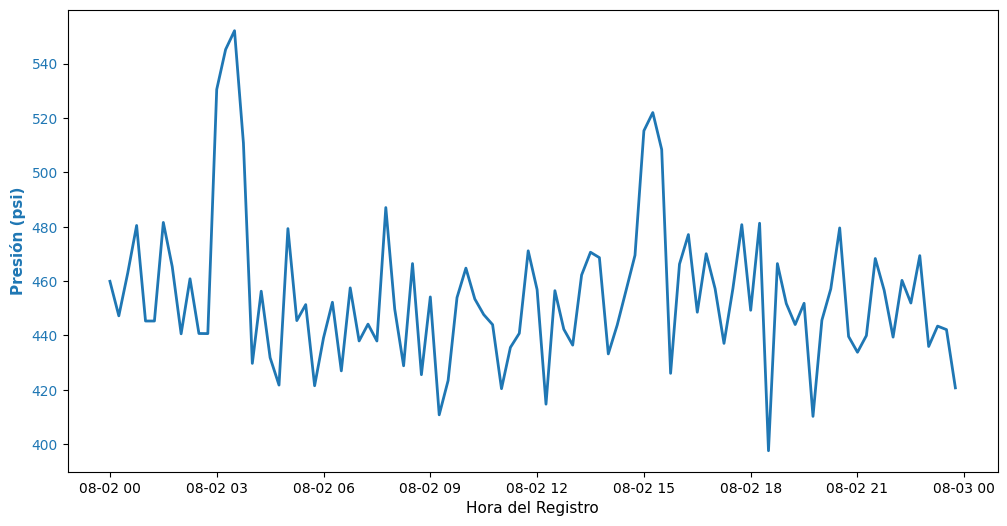

In [12]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color_presion = '#1f77b4'
ax1.set_xlabel("Hora del Registro", fontsize=11)
ax1.set_ylabel("Presión (psi)", color=color_presion, fontsize=11, fontweight="bold")

linea_p = ax1.plot(df_planta["Timestamp"], df_planta["Sensor_Presion_psi"], label="Presión de Línea (psi)", color=color_presion, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_presion)

plt.show()

### Dibujamos la línea de límite de presión (Roja discontinua)

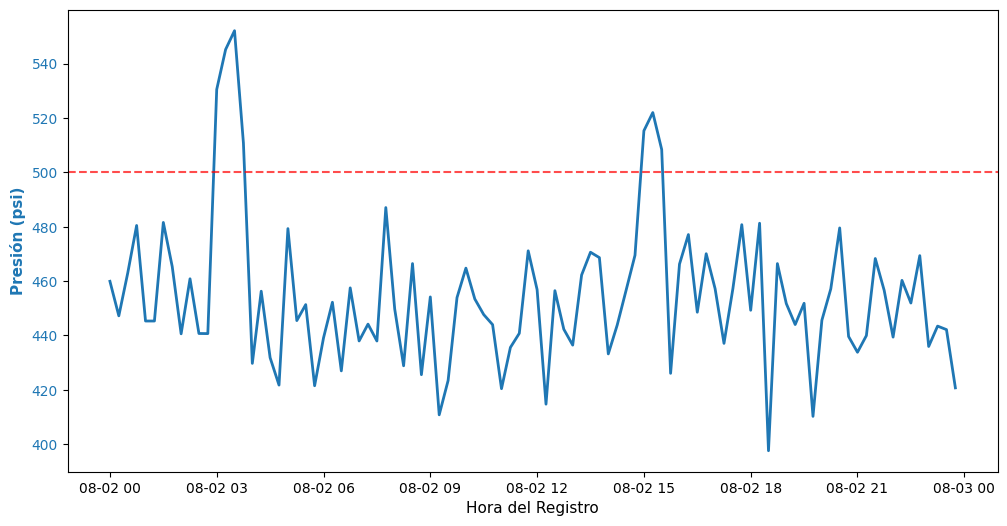

In [13]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color_presion = '#1f77b4'
ax1.set_xlabel("Hora del Registro", fontsize=11)
ax1.set_ylabel("Presión (psi)", color=color_presion, fontsize=11, fontweight="bold")

linea_p = ax1.plot(df_planta["Timestamp"], df_planta["Sensor_Presion_psi"], label="Presión de Línea (psi)", color=color_presion, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_presion)

linea_lim_p = ax1.axhline(y=LIMITE_PRESION_MAX, color="red", linestyle="--", alpha=0.7, label=f"Límite Presión ({LIMITE_PRESION_MAX} psi)")

plt.show()

### Resaltamos los puntos de falla por sobrepresión

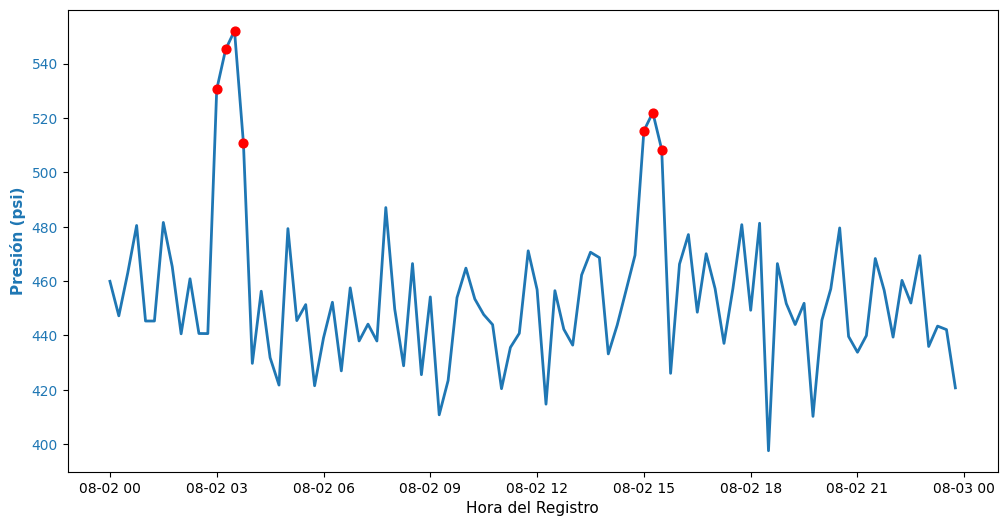

In [14]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color_presion = '#1f77b4'
ax1.set_xlabel("Hora del Registro", fontsize=11)
ax1.set_ylabel("Presión (psi)", color=color_presion, fontsize=11, fontweight="bold")

linea_p = ax1.plot(df_planta["Timestamp"], df_planta["Sensor_Presion_psi"], label="Presión de Línea (psi)", color=color_presion, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_presion)

sobrepresiones = df_planta[df_planta["Sensor_Presion_psi"] > LIMITE_PRESION_MAX]
linea_sp = ax1.scatter(sobrepresiones["Timestamp"], sobrepresiones["Sensor_Presion_psi"], color="red", s=40, zorder=5, label="Sobrepresión")

plt.show()

### Formateamos el gráfico con títulos y etiquetas industriales

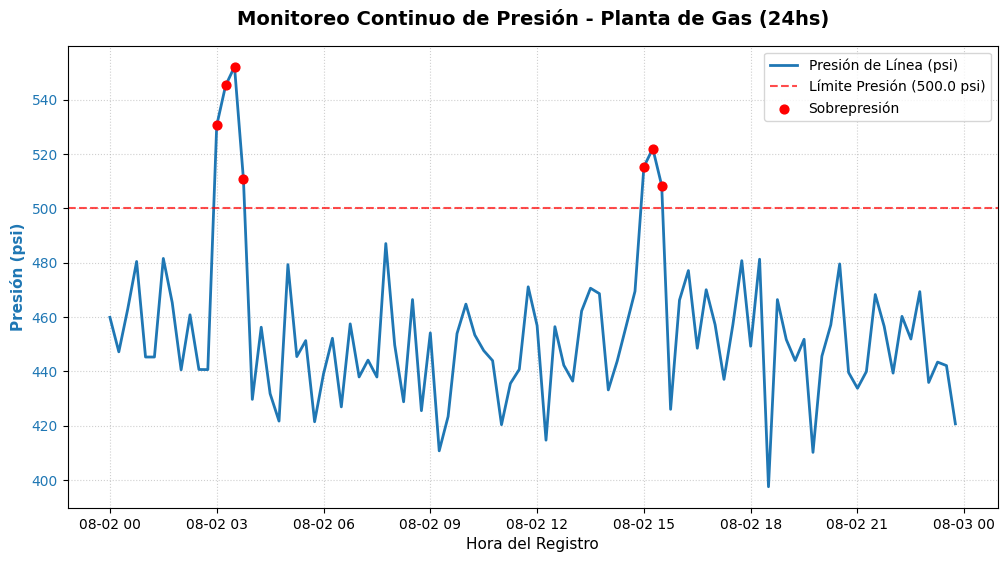

In [15]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color_presion = '#1f77b4'
ax1.set_xlabel("Hora del Registro", fontsize=11)
ax1.set_ylabel("Presión (psi)", color=color_presion, fontsize=11, fontweight="bold")

linea_p = ax1.plot(df_planta["Timestamp"], df_planta["Sensor_Presion_psi"], label="Presión de Línea (psi)", color=color_presion, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_presion)

linea_lim_p = ax1.axhline(y=LIMITE_PRESION_MAX, color="red", linestyle="--", alpha=0.7, label=f"Límite Presión ({LIMITE_PRESION_MAX} psi)")

sobrepresiones = df_planta[df_planta["Sensor_Presion_psi"] > LIMITE_PRESION_MAX]
linea_sp = ax1.scatter(sobrepresiones["Timestamp"], sobrepresiones["Sensor_Presion_psi"], color="red", s=40, zorder=5, label="Sobrepresión")

plt.title("Monitoreo Continuo de Presión - Planta de Gas (24hs)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Hora del Registro", fontsize=11)
plt.ylabel("Presión (psi)", fontsize=11)

plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc='upper right', frameon=True)

plt.show()

### Rotamos las etiquetas del tiempo para que se lean perfectamente

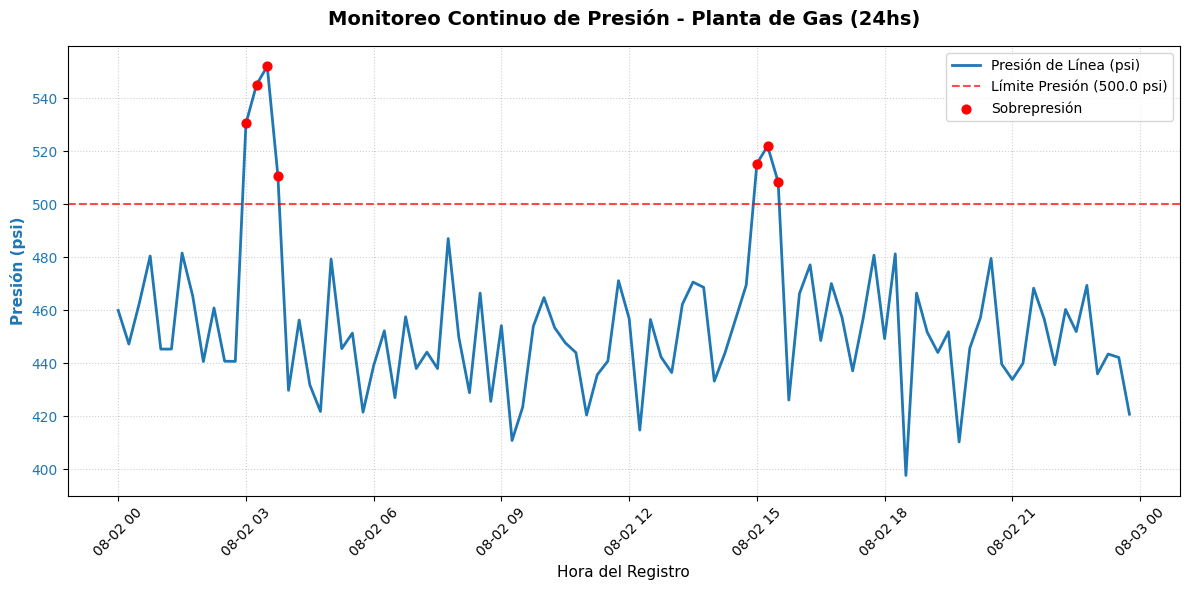

In [16]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color_presion = '#1f77b4'
ax1.set_xlabel("Hora del Registro", fontsize=11)
ax1.set_ylabel("Presión (psi)", color=color_presion, fontsize=11, fontweight="bold")

linea_p = ax1.plot(df_planta["Timestamp"], df_planta["Sensor_Presion_psi"], label="Presión de Línea (psi)", color=color_presion, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_presion)

linea_lim_p = ax1.axhline(y=LIMITE_PRESION_MAX, color="red", linestyle="--", alpha=0.7, label=f"Límite Presión ({LIMITE_PRESION_MAX} psi)")

sobrepresiones = df_planta[df_planta["Sensor_Presion_psi"] > LIMITE_PRESION_MAX]
linea_sp = ax1.scatter(sobrepresiones["Timestamp"], sobrepresiones["Sensor_Presion_psi"], color="red", s=40, zorder=5, label="Sobrepresión")

plt.title("Monitoreo Continuo de Presión - Planta de Gas (24hs)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Hora del Registro", fontsize=11)
plt.ylabel("Presión (psi)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 2. Creamos el SEGUNDO EJE (Derecha - Temperatura) compartiendo el mismo tiempo (X)

In [17]:
ax2 = ax1.twinx()

### Dibujamos la línea de Temperatura (Naranja)

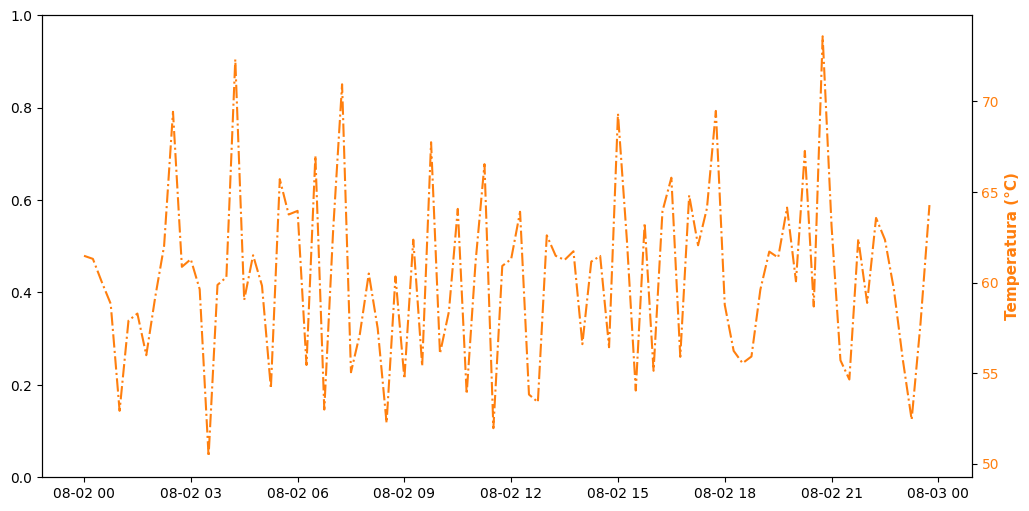

In [18]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax2 = ax1.twinx()

color_temp = '#ff7f0e'
ax2.set_ylabel("Temperatura (°C)", color=color_temp, fontsize=11, fontweight="bold")

linea_t = ax2.plot(df_planta["Timestamp"], df_planta["Sensor_Temp_C"], label="Temperatura (°C)", color=color_temp, linewidth=1.5, linestyle="-.")
ax2.tick_params(axis='y', labelcolor=color_temp)

plt.show()

### Dibujamos la línea de límite de temperatura (Naranja discontinua)

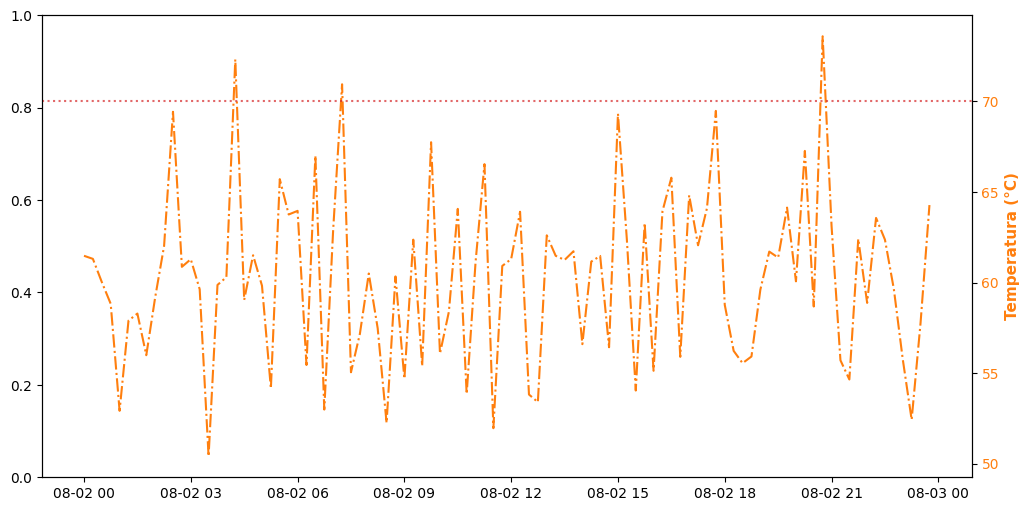

In [19]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax2 = ax1.twinx()

color_temp = '#ff7f0e'
ax2.set_ylabel("Temperatura (°C)", color=color_temp, fontsize=11, fontweight="bold")

linea_t = ax2.plot(df_planta["Timestamp"], df_planta["Sensor_Temp_C"], label="Temperatura (°C)", color=color_temp, linewidth=1.5, linestyle="-.")
ax2.tick_params(axis='y', labelcolor=color_temp)

linea_lim_t = ax2.axhline(y=LIMITE_TEMP_MAX, color="#d62728", linestyle=":", alpha=0.7, label=f"Límite Temp ({LIMITE_TEMP_MAX}°C)")

plt.show()

### Formateamos el gráfico con títulos y rotamos etiquetas

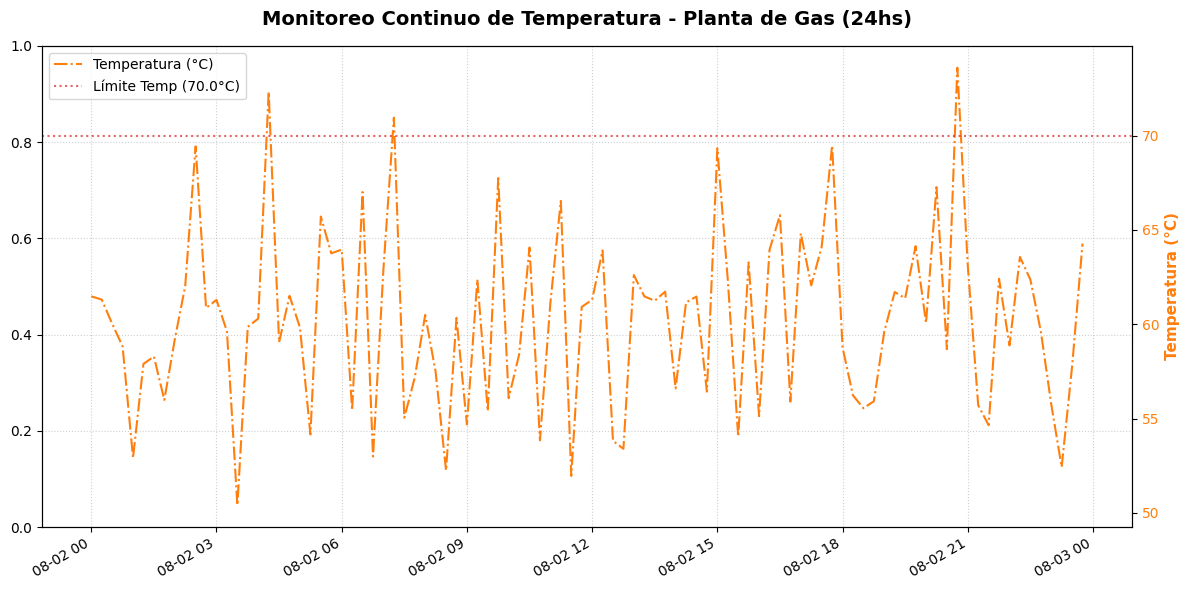

In [20]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax2 = ax1.twinx()

color_temp = '#ff7f0e'
ax2.set_ylabel("Temperatura (°C)", color=color_temp, fontsize=11, fontweight="bold")

linea_t = ax2.plot(df_planta["Timestamp"], df_planta["Sensor_Temp_C"], label="Temperatura (°C)", color=color_temp, linewidth=1.5, linestyle="-.")
ax2.tick_params(axis='y', labelcolor=color_temp)

linea_lim_t = ax2.axhline(y=LIMITE_TEMP_MAX, color="#d62728", linestyle=":", alpha=0.7, label=f"Límite Temp ({LIMITE_TEMP_MAX}°C)")

plt.title("Monitoreo Continuo de Temperatura - Planta de Gas (24hs)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Hora del Registro", fontsize=11)
plt.ylabel("Temperatura (°C)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")

fig.autofmt_xdate()
plt.tight_layout()

plt.show()

## 3. Formato final del gráfico combinado

### Unificamos las leyendas de ambos ejes en un solo cuadro y guardamos la gráfica automáticamente en una imagen de alta calidad


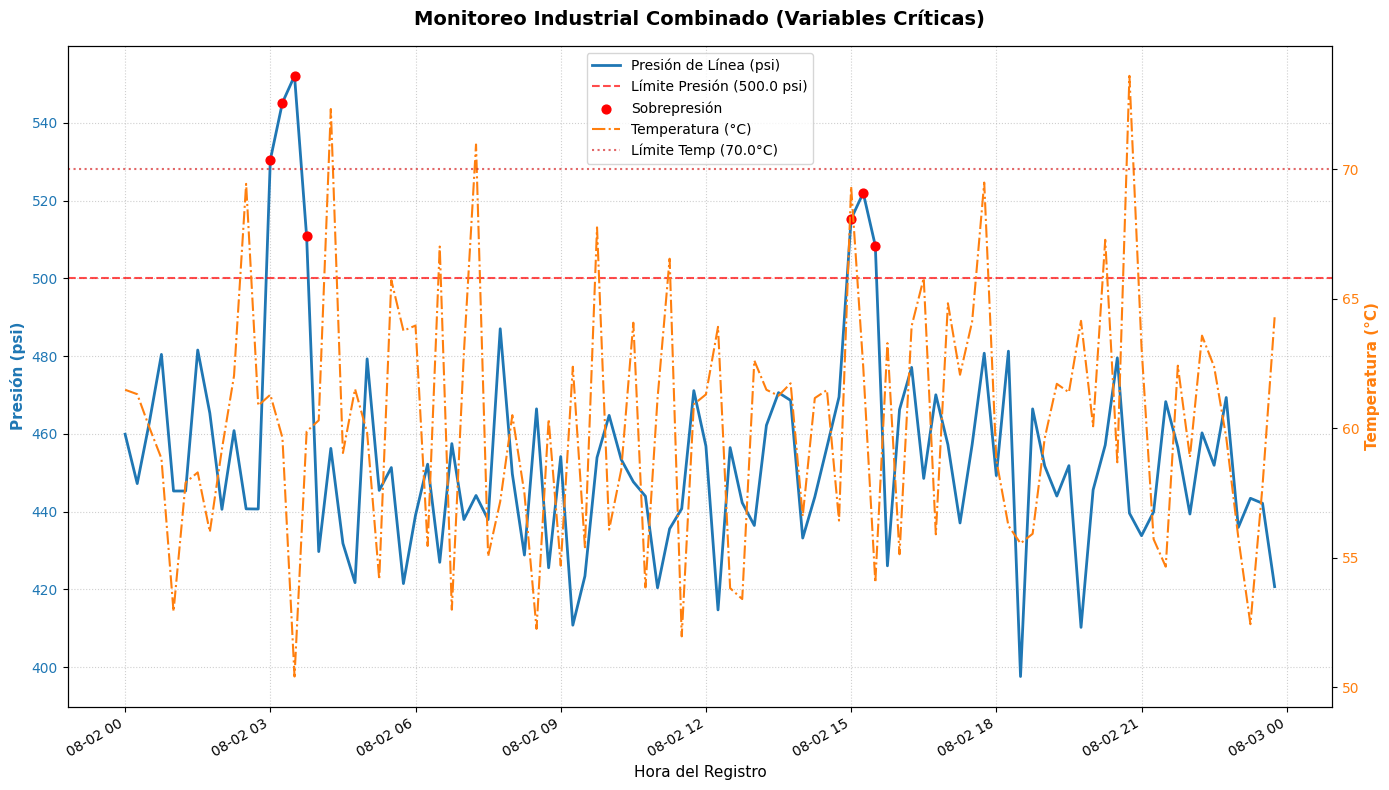

In [21]:
fig, ax1 = plt.subplots(figsize=(14, 8))

color_presion = '#1f77b4'
ax1.set_xlabel("Hora del Registro", fontsize=11)
ax1.set_ylabel("Presión (psi)", color=color_presion, fontsize=11, fontweight="bold")

linea_p = ax1.plot(df_planta["Timestamp"], df_planta["Sensor_Presion_psi"], label="Presión de Línea (psi)", color=color_presion, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_presion)

linea_lim_p = ax1.axhline(y=LIMITE_PRESION_MAX, color="red", linestyle="--", alpha=0.7, label=f"Límite Presión ({LIMITE_PRESION_MAX} psi)")

sobrepresiones = df_planta[df_planta["Sensor_Presion_psi"] > LIMITE_PRESION_MAX]
linea_sp = ax1.scatter(sobrepresiones["Timestamp"], sobrepresiones["Sensor_Presion_psi"], color="red", s=40, zorder=5, label="Sobrepresión")

ax2 = ax1.twinx()

color_temp = '#ff7f0e'
ax2.set_ylabel("Temperatura (°C)", color=color_temp, fontsize=11, fontweight="bold")

linea_t = ax2.plot(df_planta["Timestamp"], df_planta["Sensor_Temp_C"], label="Temperatura (°C)", color=color_temp, linewidth=1.5, linestyle="-.")
ax2.tick_params(axis='y', labelcolor=color_temp)

linea_lim_t = ax2.axhline(y=LIMITE_TEMP_MAX, color="#d62728", linestyle=":", alpha=0.7, label=f"Límite Temp ({LIMITE_TEMP_MAX}°C)")

plt.title("Monitoreo Industrial Combinado (Variables Críticas)", fontsize=14, fontweight="bold", pad=15)
ax1.grid(True, linestyle=":", alpha=0.6)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

manejadores_totales = handles1 + handles2
etiquetas_totales = labels1 + labels2

ax1.legend(manejadores_totales, etiquetas_totales, loc="upper center", frameon=True)

fig.autofmt_xdate()
plt.tight_layout()

# --- LÍNEA PARA GUARDAR EN ALTA CALIDAD ---
nombre_grafica = "monitoreo_completo_planta.png"
plt.savefig(nombre_grafica, dpi=300, bbox_inches="tight")

plt.show()

In [22]:
print(f"¡Gráfica exportada con éxito como: '{nombre_grafica}'!")

¡Gráfica exportada con éxito como: 'monitoreo_completo_planta.png'!


# 4. EXPORTACIÓN DEL REPORTE A CSV (Lógica previa)

### Automatización del reporte técnico

In [23]:
if not reporte_alertas.empty:
    condiciones_diagnostico = [
        (reporte_alertas["Sensor_Presion_psi"] > LIMITE_PRESION_MAX) & (reporte_alertas["Sensor_Temp_C"] > LIMITE_TEMP_MAX),
        (reporte_alertas["Sensor_Presion_psi"] > LIMITE_PRESION_MAX),
        (reporte_alertas["Sensor_Temp_C"] > LIMITE_TEMP_MAX)
    ]
    mensajes = [
        "CRÍTICO: Sobrepresión y Alta Temperatura en simultáneo.",
        "ALERTA: Sobrepresión detectada. Revisar línea de alivio.",
        "ALERTA: Alta Temperatura detectada. Revisar sistema de refrigeración."
    ]
    reporte_alertas["Diagnostico"] = np.select(condiciones_diagnostico, mensajes, default="Revisar sensor")


### Guardamos el archivo base

In [24]:
nombre_archivo = "Alertas_Variables_Planta.csv"
# Usamos sep=";" para que Excel en español separe las columnas correctamente de forma automática
reporte_alertas.to_csv(nombre_archivo, index=False, sep=';', encoding="utf-8-sig")

### Mostramos en pantalla el resultado con las columnas clave

In [25]:
print("\nVista previa del reporte de planta:")
print(reporte_alertas[["Timestamp", "Sensor_Presion_psi", "Sensor_Temp_C", "Diagnostico"]].head(10))


Vista previa del reporte de planta:
             Timestamp  Sensor_Presion_psi  Sensor_Temp_C  \
12 2026-08-02 03:00:00              530.50          61.29   
13 2026-08-02 03:15:00              545.20          59.63   
14 2026-08-02 03:30:00              552.10          50.41   
15 2026-08-02 03:45:00              510.80          59.87   
17 2026-08-02 04:15:00              456.28          72.32   
29 2026-08-02 07:15:00              444.17          70.95   
60 2026-08-02 15:00:00              515.30          69.33   
61 2026-08-02 15:15:00              522.00          62.37   
62 2026-08-02 15:30:00              508.40          54.04   
83 2026-08-02 20:45:00              439.63          73.60   

                                          Diagnostico  
12  ALERTA: Sobrepresión detectada. Revisar línea ...  
13  ALERTA: Sobrepresión detectada. Revisar línea ...  
14  ALERTA: Sobrepresión detectada. Revisar línea ...  
15  ALERTA: Sobrepresión detectada. Revisar línea ...  
17  ALERTA: